<a href="https://colab.research.google.com/github/Papawadee-Mohdee/US-Accidents-Severity-Prediction/blob/toto/MiniProject_Part2_BigData_ML_Copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Big Data Analytics
## Part 2: Data Management and Machine Learning Pipeline

**ชื่อกลุ่ม:** ...

**รายชื่อสมาชิก การแบ่งงาน และสัดส่วนในการทำงาน (5 คน):**

| # | ชื่อ-สกุล | รหัสนักศึกษา | หน้าที่หลัก | สัดส่วน (%) |
|---|---|---|---|---|
| 1 | ... | ... | ... | ... |
| 2 | ... | ... | ... | ... |
| 3 | ... | ... | ... | ... |
| 4 | ... | ... | ... | ... |
| 5 | ... | ... | ... | ... |

**กำหนดส่ง:** ...

**นำเสนอในชั้นเรียน:** ...

---
### NOTE
* ใช้ข้อมูลสาธารณะที่มี **อย่างน้อย 1 ล้านแถว** (แจ้งชื่อชุดข้อมูลกับอาจารย์ ห้ามซ้ำกับกลุ่มอื่น)
* รันที่ใดก็ได้ เช่น Google Colab (free), Kaggle หรือเครื่องตนเอง
* ส่ง notebook ที่ **รันครบทุกเซลล์และแสดงผลลัพธ์** (ลิงก์ต้องเปิดได้)
* บันทึกงานเป็นประจำ และเริ่มทำแต่เนิ่น ๆ อาจารย์ไม่รับปรึกษาในคืนก่อนส่ง

## ตัวอย่างชุดข้อมูล (เลือกจากนี้ หรือเสนอชุดอื่นที่มีอย่างน้อย 5 แสนแถว แต่ถ้าเป็นข้อมูลภาพหรือข้อความมีอย่างน้อย 1000 หน่วย)

| ชุดข้อมูล | ลิงก์ | ตัวอย่างคำถาม | นำไปใช้ประโยชน์ |
|---|---|---|---|
| US Accidents (Kaggle) | [Kaggle](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents) | ทำนายความรุนแรงของอุบัติเหตุ | วางแผนจุดเสี่ยงและการตอบสนองเหตุ |
| Lending Club Loan Data (Kaggle) | [Kaggle](https://www.kaggle.com/datasets/wordsforthewise/lending-club) | ทำนายการผิดนัดชำระหนี้ | พิจารณาสินเชื่อ |
| US Flight On-Time Performance (BTS) | [BTS TranStats](https://www.transtats.bts.gov/DatabaseInfo.asp?QO_VQ=EFD) | ทำนายเที่ยวบินล่าช้า | วางแผนการเดินทาง, ตารางบิน |
| NYC 311 Service Requests | [2020 ถึงปัจจุบัน](https://data.cityofnewyork.us/d/erm2-nwe9)<br>[2010 ถึง 2019](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2010-to-2019/76ig-c548/about_data) | ทำนายระยะเวลาปิดเรื่องร้องเรียน | จัดสรรเจ้าหน้าที่ |
| NYC Taxi / Citi Bike Trip Data | [NYC Taxi (TLC)](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)<br>[Citi Bike](https://citibikenyc.com/system-data) | พยากรณ์ความต้องการรายพื้นที่รายชั่วโมง | จัดสรรรถ/จักรยาน |
| Amazon Reviews 2023 (บาง category) | [Amazon Reviews'23](https://amazon-reviews-2023.github.io/) | ทำนาย rating หรือ sentiment จากรีวิว | ปรับปรุงสินค้า/บริการ |
| ข้อมูลคุณภาพอากาศและจุดความร้อน (Air4Thai, NASA FIRMS) | [PM2.5 รายชั่วโมง Air4Thai (OpenAQ)](https://explore.openaq.org)<br>[NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/download/) | พยากรณ์ PM2.5 | แจ้งเตือนประชาชน |

## 1. ปัญหาและคำถามที่สนใจ
**ปัญหา/คำถามที่สนใจคืออะไร**

...

**ปัญหา/คำถามนี้มีความสำคัญอย่างไร และใครจะนำผลไปใช้**

...

**เป้าหมาย (target) และประเภทงาน (classification / regression / unsupervised)**

...

## 2. Data Description
* แหล่งข้อมูล (ลิงก์) และช่วงเวลาของข้อมูล

แหล้งข้อมูล kaggle ช่วงเวลาตั้งแต่กุมภาพันธ์ 2559 ถึงเดือนมีนาคม 2566
* จำนวนแถว จำนวนคอลัมน์ และความหมายของแต่ละคอลัมน์ที่ใช้ (data dictionary)

จำนวน 7728394 row และ 46 column
* ข้อมูล 1 แถว แทนอะไร (unit of analysis)

ข้อมูล 1 แถวคือ 1 เหตุการณ์

## 3. Data Loading

####Data Loading from Drive CSV

In [ ]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import os
import gc
import pyarrow.dataset as ds

In [ ]:
!pip install -q pyarrow

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load data
input_file = ("/content/drive/MyDrive/dataset/US_Accidents_March23.csv")
output_dir = "/content/drive/MyDrive/dataset/parquet"
# Merge data if necessary (ระบุ key ที่ใช้ และตรวจจำนวนแถวก่อนและหลัง merge)

In [ ]:
base_path = "/content/drive/MyDrive"
for root, dirs, files in os.walk(base_path):
    for file in files:
        if "US_Accidents_March23" in file:
            print(os.path.join(root, file))

/content/drive/MyDrive/dataset/US_Accidents_March23.csv


In [ ]:
os.makedirs(output_dir, exist_ok=True)
chunksize = 100_000
for i, chunk in enumerate(
    pd.read_csv(input_file, chunksize=chunksize)
):
    output_file = os.path.join(
        output_dir, f"part_{i:04d}.parquet"
    )
    chunk.to_parquet(
        output_file,
        engine="pyarrow",
        compression="snappy",
        index=False
    )
    print(f"Chunk {i}: {len(chunk):,} rows saved")
    del chunk
    gc.collect()
print("Conversion completed!")

####Data Loading from Drive Parquet

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pyarrow.dataset as ds
dataset = ds.dataset("/content/drive/MyDrive/dataset/parquet", format="parquet")

In [ ]:
dataset

In [ ]:
print(dataset.schema)

ID: string
Source: string
Severity: int64
Start_Time: string
End_Time: string
Start_Lat: double
Start_Lng: double
End_Lat: double
End_Lng: double
Distance(mi): double
Description: string
Street: string
City: string
County: string
State: string
Zipcode: string
Country: string
Timezone: string
Airport_Code: string
Weather_Timestamp: string
Temperature(F): double
Wind_Chill(F): double
Humidity(%): double
Pressure(in): double
Visibility(mi): double
Wind_Direction: string
Wind_Speed(mph): double
Precipitation(in): double
Weather_Condition: string
Amenity: bool
Bump: bool
Crossing: bool
Give_Way: bool
Junction: bool
No_Exit: bool
Railway: bool
Roundabout: bool
Station: bool
Stop: bool
Traffic_Calming: bool
Traffic_Signal: bool
Turning_Loop: bool
Sunrise_Sunset: string
Civil_Twilight: string
Nautical_Twilight: string
Astronomical_Twilight: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 5567


In [ ]:
# นับจำนวนแถวทั้งหมดโดยไม่โหลดข้อมูลเข้า Memory
total_rows = sum(fragment.count_rows() for fragment in dataset.get_fragments())
total_rows

7728394

In [ ]:
# ดึงข้อมูล 5 แถวแรก แสดงในรูปแบบ pandas DataFrame
head_df = dataset.head(5).to_pandas()
display(head_df)

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


In [ ]:
# ตรวจสอบจำนวนแถวทั้งหมดก่อนเพื่อใช้คำนวณเปอร์เซ็นต์
total_rows = sum(fragment.count_rows() for fragment in dataset.get_fragments())

# วนลูปอ่านข้อมูลทีละ batch เพื่อรวมจำนวน Missing ของทุกคอลัมน์
missing_series = pd.Series(0, index=dataset.schema.names)

for batch in dataset.to_batches():
    # แปลง batch ย่อยเป็น pandas และนับ null ของคอลัมน์ต่าง ๆ
    chunk_missing = batch.to_pandas().isna().sum()
    missing_series = missing_series.add(chunk_missing, fill_value=0)

# สร้างตารางสรุปรายงาน
missing_report = pd.DataFrame({
    'Missing_Count': missing_series.astype('int64'),
    'Missing_Percent': ((missing_series / total_rows) * 100).round(2)})

# เรียงลำดับจากคอลัมน์ที่ข้อมูลหายไปมากที่สุด
missing_report = missing_report.sort_values(by='Missing_Percent', ascending=False)

print(f"จำนวนแถวที่ตรวจสอบเสร็จสิ้น: {total_rows:,} แถว")
display(missing_report) #00.47 วินาที

จำนวนแถวที่ตรวจสอบเสร็จสิ้น: 7,728,394 แถว


,Missing_Count,Missing_Percent
End_Lng,3402762,44.03
End_Lat,3402762,44.03
Precipitation(in),2203586,28.51
Wind_Chill(F),1999019,25.87
Wind_Speed(mph),571233,7.39
Visibility(mi),177098,2.29
Wind_Direction,175206,2.27
Humidity(%),174144,2.25
Weather_Condition,173459,2.24
Temperature(F),163853,2.12


In [ ]:
# ดึงคอลัมน์เกี่ยวกับสภาพอากาศและอุณหภูมิ
weather_cols = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']

# โหลดข้อมูลมาตรวจสอบในรูปแบบ Pandas DataFrame เฉพาะคอลัมน์ที่จำเป็น
weather_df = dataset.to_table(columns=weather_cols).to_pandas()

print("=== สรุปข้อมูลทางสถิติเบื้องหลังของคอลัมน์สภาพอากาศ ===")
display(weather_df.describe())

print("\n=== วิเคราะห์หา Outliers (ค่าที่ผิดปกติสูง/ต่ำ เกินจริง) ===")
for col in weather_cols:
    q1 = weather_df[col].quantile(0.25)
    q3 = weather_df[col].quantile(0.75)
    iqr = q3 - q1

    # คำนวณขอบเขตล่างและขอบบน (Upper/Lower Bound)
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # หาจำนวนแถวที่เป็น Outliers
    outliers = weather_df[(weather_df[col] < lower_bound) | (weather_df[col] > upper_bound)][col]
    max_val = weather_df[col].max()
    min_val = weather_df[col].min()

    print(f"\nคอลัมน์: {col}")
    print(f"  - ค่าต่ำสุดที่พบ: {min_val} | ค่าสูงสุดที่พบ: {max_val}")
    print(f"  - ช่วงข้อมูลปกติ (IQR Bound): {lower_bound:.2f} ถึง {upper_bound:.2f}")
    print(f"  - จำนวนแถวที่เป็น Outlier: {len(outliers):,} จากทั้งหมด ({len(outliers)/len(weather_df)*100:.2f}%)")

=== สรุปข้อมูลทางสถิติเบื้องหลังของคอลัมน์สภาพอากาศ ===


,Temperature(F),Wind_Chill(F),Humidity(%),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,7.564541e+06,5.729375e+06,7.554250e+06,7.551296e+06,7.157161e+06,5.524808e+06
mean,6.166329e+01,5.825105e+01,6.483104e+01,9.090376e+00,7.685490e+00,8.407210e-03
std,1.901365e+01,2.238983e+01,2.282097e+01,2.688316e+00,5.424983e+00,1.102246e-01
min,-8.900000e+01,-8.900000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.900000e+01,4.300000e+01,4.800000e+01,1.000000e+01,4.600000e+00,0.000000e+00
50%,6.400000e+01,6.200000e+01,6.700000e+01,1.000000e+01,7.000000e+00,0.000000e+00
75%,7.600000e+01,7.500000e+01,8.400000e+01,1.000000e+01,1.040000e+01,0.000000e+00
max,2.070000e+02,2.070000e+02,1.000000e+02,1.400000e+02,1.087000e+03,3.647000e+01



=== วิเคราะห์หา Outliers (ค่าที่ผิดปกติสูง/ต่ำ เกินจริง) ===

คอลัมน์: Temperature(F)
  - ค่าต่ำสุดที่พบ: -89.0 | ค่าสูงสุดที่พบ: 207.0
  - ช่วงข้อมูลปกติ (IQR Bound): 8.50 ถึง 116.50
  - จำนวนแถวที่เป็น Outlier: 50,515 จากทั้งหมด (0.65%)

คอลัมน์: Wind_Chill(F)
  - ค่าต่ำสุดที่พบ: -89.0 | ค่าสูงสุดที่พบ: 207.0
  - ช่วงข้อมูลปกติ (IQR Bound): -5.00 ถึง 123.00
  - จำนวนแถวที่เป็น Outlier: 43,869 จากทั้งหมด (0.57%)

คอลัมน์: Humidity(%)
  - ค่าต่ำสุดที่พบ: 1.0 | ค่าสูงสุดที่พบ: 100.0
  - ช่วงข้อมูลปกติ (IQR Bound): -6.00 ถึง 138.00
  - จำนวนแถวที่เป็น Outlier: 0 จากทั้งหมด (0.00%)

คอลัมน์: Visibility(mi)
  - ค่าต่ำสุดที่พบ: 0.0 | ค่าสูงสุดที่พบ: 140.0
  - ช่วงข้อมูลปกติ (IQR Bound): 10.00 ถึง 10.00
  - จำนวนแถวที่เป็น Outlier: 1,481,065 จากทั้งหมด (19.16%)

คอลัมน์: Wind_Speed(mph)
  - ค่าต่ำสุดที่พบ: 0.0 | ค่าสูงสุดที่พบ: 1087.0
  - ช่วงข้อมูลปกติ (IQR Bound): -4.10 ถึง 19.10
  - จำนวนแถวที่เป็น Outlier: 210,603 จากทั้งหมด (2.73%)

คอลัมน์: Precipitation(in)
  - ค่าต่ำสุดที่พบ: 0.0 | 

In [ ]:
import pandas as pd

# ดึงข้อมูลเฉพาะคอลัมน์ Severity จาก Dataset
severity_table = dataset.to_table(columns=['Severity'])
severity_df = severity_table.to_pandas()

# คำนวณจำนวนแถวและร้อยละของแต่ละระดับความรุนแรง
severity_counts = severity_df['Severity'].value_counts().sort_index()
severity_percent = (severity_df['Severity'].value_counts(normalize=True) * 100).sort_index()

# แสดงผลลัพธ์เป็น DataFrame
severity_report = pd.DataFrame({
    'Count (จำนวนครั้ง)': severity_counts,
    'Percentage (ร้อยละ)': severity_percent.round(2)
})

print("=== การกระจายตัวของระดับความรุนแรงของอุบัติเหตุ (Severity) ===")
display(severity_report)

=== การกระจายตัวของระดับความรุนแรงของอุบัติเหตุ (Severity) ===


,Count (จำนวนครั้ง),Percentage (ร้อยละ)
Severity,,
1,67366,0.87
2,6156981,79.67
3,1299337,16.81
4,204710,2.65


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

# 1. โหลดข้อมูล Severity และตัวแปรด้านสภาพอากาศที่สำคัญ
analysis_cols = ['Severity', 'Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
df_stat = dataset.to_table(columns=analysis_cols).to_pandas()

# 2. แบ่งกลุ่มความรุนแรง: 1-2 คือ 'น้อย (Low)' และ 3-4 คือ 'รุนแรง (Severe)'
df_stat['Severity_Group'] = np.where(df_stat['Severity'].isin([1, 2]), 'Low', 'Severe')

group_low = df_stat[df_stat['Severity_Group'] == 'Low']
group_severe = df_stat[df_stat['Severity_Group'] == 'Severe']

print(f"จำนวนอุบัติเหตุกลุ่มรุนแรงน้อย (Severity 1-2): {len(group_low):,} เคส")
print(f"จำนวนอุบัติเหตุกลุ่มรุนแรงมาก (Severity 3-4): {len(group_severe):,} เคส\n")

# 3. รัน Mann-Whitney U Test สำหรับตัวแปรสภาพอากาศหลักๆ
results = []
variables = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)']

print("=== ผลการทดสอบ Mann-Whitney U Test ===")
for var in variables:
    # ตัดค่า Missing (NaN) ออกสำหรับการทดสอบ
    data_low = group_low[var].dropna()
    data_severe = group_severe[var].dropna()

    # คำนวณ Mann-Whitney U Test
    stat, p_val = mannwhitneyu(data_low, data_severe, alternative='two-sided')

    # สรุปค่ามัธยฐานของแต่ละกลุ่ม
    median_low = data_low.median()
    median_severe = data_severe.median()

    # การสรุปผล
    sig = "มีความแตกต่างกันอย่างมีนัยสำคัญทางสถิติ (p < 0.05)" if p_val < 0.05 else "ไม่มีความแตกต่างกันอย่างมีนัยสำคัญทางสถิติ"

    print(f"\nตัวแปร: {var}")
    print(f"  - ค่ามัธยฐานกลุ่มรุนแรงน้อย (Low): {median_low}")
    print(f"  - ค่ามัธยฐานกลุ่มรุนแรงมาก (Severe): {median_severe}")
    print(f"  - U-statistic: {stat:,.1f} | p-value: {p_val:.3e}")
    print(f"  - สรุปผล: {sig}")

จำนวนอุบัติเหตุกลุ่มรุนแรงน้อย (Severity 1-2): 6,224,347 เคส
จำนวนอุบัติเหตุกลุ่มรุนแรงมาก (Severity 3-4): 1,504,047 เคส

=== ผลการทดสอบ Mann-Whitney U Test ===

ตัวแปร: Temperature(F)
  - ค่ามัธยฐานกลุ่มรุนแรงน้อย (Low): 64.0
  - ค่ามัธยฐานกลุ่มรุนแรงมาก (Severe): 64.0
  - U-statistic: 4,474,835,198,840.5 | p-value: 7.280e-04
  - สรุปผล: มีความแตกต่างกันอย่างมีนัยสำคัญทางสถิติ (p < 0.05)

ตัวแปร: Humidity(%)
  - ค่ามัธยฐานกลุ่มรุนแรงน้อย (Low): 67.0
  - ค่ามัธยฐานกลุ่มรุนแรงมาก (Severe): 68.0
  - U-statistic: 4,372,934,659,323.5 | p-value: 0.000e+00
  - สรุปผล: มีความแตกต่างกันอย่างมีนัยสำคัญทางสถิติ (p < 0.05)

ตัวแปร: Visibility(mi)
  - ค่ามัธยฐานกลุ่มรุนแรงน้อย (Low): 10.0
  - ค่ามัธยฐานกลุ่มรุนแรงมาก (Severe): 10.0
  - U-statistic: 4,499,929,582,765.5 | p-value: 1.882e-125
  - สรุปผล: มีความแตกต่างกันอย่างมีนัยสำคัญทางสถิติ (p < 0.05)

ตัวแปร: Wind_Speed(mph)
  - ค่ามัธยฐานกลุ่มรุนแรงน้อย (Low): 7.0
  - ค่ามัธยฐานกลุ่มรุนแรงมาก (Severe): 8.0
  - U-statistic: 3,592,262,902,856.5 | 

In [ ]:
import pyarrow.compute as pc
import pyarrow.dataset as ds

# 2. กำหนดคอลัมน์ที่ต้องการใช้จริง (Projection)
selected_cols = [
    # Target
    "Severity",
    # เวลา
    "Start_Time",
    # สถานที่
    "State",
    "Start_Lat",
    "Start_Lng",
    # สภาพอากาศ
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Wind_Direction",
    "Weather_Condition",
    # ลักษณะถนน
    "Amenity",
    "Bump",
    "Crossing",
    "Give_Way",
    "Junction",
    "No_Exit",
    "Railway",
    "Roundabout",
    "Station",
    "Stop",
    "Traffic_Calming",
    "Traffic_Signal",
    # กลางวัน/กลางคืน
    "Sunrise_Sunset",]
raw_df = dataset.to_table(columns=selected_cols).to_pandas()
display(raw_df.head())

,Severity,Start_Time,State,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset
0,3,2016-02-08 05:46:00,OH,39.865147,-84.058723,36.9,91.0,29.68,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
1,2,2016-02-08 06:07:59,OH,39.928059,-82.831184,37.9,100.0,29.65,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
2,2,2016-02-08 06:49:27,OH,39.063148,-84.032608,36.0,100.0,29.67,10.0,3.5,...,False,False,False,False,False,False,False,False,True,Night
3,3,2016-02-08 07:23:34,OH,39.747753,-84.205582,35.1,96.0,29.64,9.0,4.6,...,False,False,False,False,False,False,False,False,False,Night
4,2,2016-02-08 07:39:07,OH,39.627781,-84.188354,36.0,89.0,29.65,6.0,3.5,...,False,False,False,False,False,False,False,False,True,Day


## 4. Data Quality Assessment
ตรวจและรายงานเป็นตัวเลข: ชนิดข้อมูล, missing values, ข้อมูลซ้ำ, ค่าผิดปกติ/เป็นไปไม่ได้, ความไม่สอดคล้องของข้อมูล

In [ ]:
# Data types and memory usage

# Missing values (จำนวนและร้อยละต่อคอลัมน์)

# Duplicates

# Invalid / impossible values และ outliers

In [ ]:
import gc, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds

In [ ]:
# Data types and memory usage
n_rows = len(raw_df)
mem_before = raw_df.memory_usage(deep=True).sum() / 1e9
print(f"แถว: {n_rows:,} | คอลัมน์: {raw_df.shape[1]} | หน่วยความจำก่อนปรับ: {mem_before:.2f} GB")

# (1) Start_Time: ถ้าเป็นข้อความ ให้แปลงเป็น datetime (ISO8601 รองรับทั้งแบบมีและไม่มีเศษวินาที)
if not pd.api.types.is_datetime64_any_dtype(raw_df["Start_Time"]):
    n_before = int(raw_df["Start_Time"].isna().sum())
    raw_df["Start_Time"] = pd.to_datetime(raw_df["Start_Time"], format="ISO8601", errors="coerce")
    n_new = int(raw_df["Start_Time"].isna().sum()) - n_before
    print(f"Start_Time แปลงเป็น datetime แล้ว | NaT ที่เพิ่มจากการแปลง = {n_new:,}  (ต้องเป็น 0)")

# (2) ข้อความ -> category เพื่อประหยัดหน่วยความจำ
text_cols = [c for c in raw_df.columns
             if raw_df[c].dtype == object or pd.api.types.is_string_dtype(raw_df[c].dtype)]
for c in text_cols:
    raw_df[c] = raw_df[c].astype("category")
gc.collect()

mem_after = raw_df.memory_usage(deep=True).sum() / 1e9
print(f"แปลงเป็น category: {text_cols}")
print(f"หน่วยความจำหลังปรับ: {mem_after:.2f} GB (ลดลง {(1 - mem_after / mem_before) * 100:.0f}%)")

dtype_table = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "memory_MB": (raw_df.memory_usage(deep=True).drop("Index") / 1e6).round(1),
})
display(dtype_table["dtype"].value_counts().to_frame("จำนวนคอลัมน์"))
display(dtype_table)

แถว: 7,728,394 | คอลัมน์: 26 | หน่วยความจำก่อนปรับ: 0.75 GB
แปลงเป็น category: []
หน่วยความจำหลังปรับ: 0.75 GB (ลดลง 0%)


,จำนวนคอลัมน์
dtype,
bool,12
float64,8
category,4
int64,1
datetime64[ns],1


,dtype,memory_MB
Severity,int64,61.8
Start_Time,datetime64[ns],61.8
State,category,7.7
Start_Lat,float64,61.8
Start_Lng,float64,61.8
Temperature(F),float64,61.8
Humidity(%),float64,61.8
Pressure(in),float64,61.8
Visibility(mi),float64,61.8
Wind_Speed(mph),float64,61.8


คอลัมน์ที่มี missing: 9 จาก 26 คอลัมน์ | ไม่มี missing: 17 คอลัมน์


,missing_count,missing_pct
Precipitation(in),2203586,28.51
Wind_Speed(mph),571233,7.39
Visibility(mi),177098,2.29
Wind_Direction,175206,2.27
Humidity(%),174144,2.25
Weather_Condition,173459,2.24
Temperature(F),163853,2.12
Pressure(in),140679,1.82
Sunrise_Sunset,23246,0.30
Severity,0,0.00


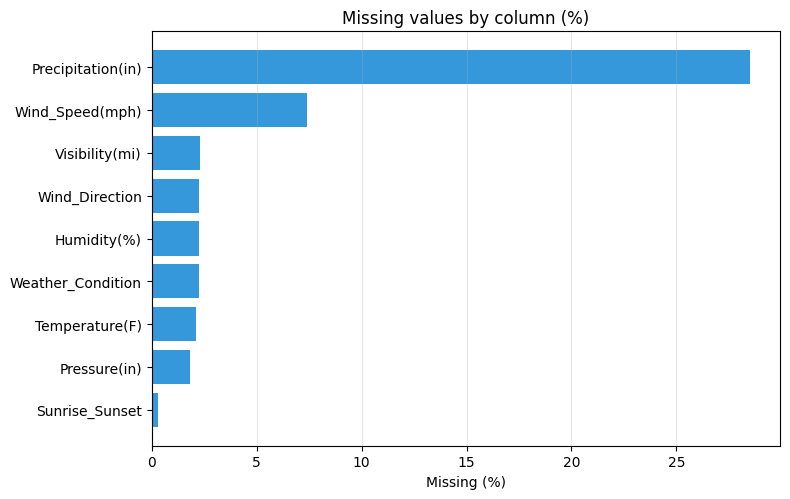

In [ ]:
# Missing values (จำนวนและร้อยละต่อคอลัมน์)
miss = raw_df.isna().sum()
miss_df = (miss.to_frame("missing_count")
           .assign(missing_pct=lambda d: d["missing_count"] / n_rows * 100)
           .sort_values("missing_count", ascending=False))
has_missing = miss_df[miss_df["missing_count"] > 0]
print(f"คอลัมน์ที่มี missing: {len(has_missing)} จาก {len(miss_df)} คอลัมน์ | ไม่มี missing: {(miss_df['missing_count'] == 0).sum()} คอลัมน์")
display(miss_df.round(2))

if len(has_missing) > 0:
    plot_df = has_missing.sort_values("missing_pct")
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(plot_df) + 1.5))
    ax.barh(plot_df.index, plot_df["missing_pct"], color="#3498db")
    ax.set_xlim(left=0)
    ax.set_xlabel("Missing (%)"); ax.set_title("Missing values by column (%)"); ax.grid(axis="x", alpha=0.3)
    plt.tight_layout(); plt.show()

In [ ]:
# Duplicates
dup_mask = raw_df.duplicated(keep="first")
n_dup = int(dup_mask.sum())
print(f"แถวซ้ำทุกคอลัมน์ที่เลือก: {n_dup:,} ({n_dup / n_rows * 100:.4f}%)")

key_cols = ["Start_Time", "Start_Lat", "Start_Lng"]
n_dup_key = int(raw_df.duplicated(subset=key_cols, keep="first").sum())
print(f"แถวที่เวลาและพิกัดเดียวกัน (ซ้ำเฉพาะ {key_cols}): {n_dup_key:,} ({n_dup_key / n_rows * 100:.4f}%)")

if n_dup > 0:
    print("\nตัวอย่างแถวที่ซ้ำ:")
    display(raw_df[dup_mask].head(5))
del dup_mask
gc.collect()

แถวซ้ำทุกคอลัมน์ที่เลือก: 487,992 (6.3143%)
แถวที่เวลาและพิกัดเดียวกัน (ซ้ำเฉพาะ ['Start_Time', 'Start_Lat', 'Start_Lng']): 541,603 (7.0080%)

ตัวอย่างแถวที่ซ้ำ:


,Severity,Start_Time,State,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset
1924,3,2016-07-02 09:29:38,CA,38.216862,-122.137840,60.1,78.0,29.96,10.0,13.8,...,False,False,False,False,False,False,False,False,False,Day
3941,2,2016-07-23 07:40:11,CA,37.226570,-121.975113,64.9,70.0,29.99,10.0,NaN,...,False,True,False,False,False,False,False,False,False,Day
4288,2,2016-07-26 12:51:17,CA,37.119865,-121.975967,89.6,29.0,29.87,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Day
17910,2,2016-11-21 07:02:28,CA,38.501335,-122.431770,41.0,100.0,29.99,0.2,NaN,...,False,False,False,False,False,False,False,False,False,Day
27591,3,2016-08-17 09:14:48,CA,37.317421,-121.935356,64.0,70.0,29.88,6.0,4.6,...,False,False,False,False,False,False,False,False,False,Day


9

In [ ]:
# Invalid / impossible values และ outliers
RULES = {
    "Severity": (1, 4), "Humidity(%)": (0, 100), "Temperature(F)": (-80, 135), "Pressure(in)": (25, 33),
    "Visibility(mi)": (0, 100), "Wind_Speed(mph)": (0, 250), "Precipitation(in)": (0, 25),
    "Start_Lat": (18, 72), "Start_Lng": (-180, -65),
}
rows = []
for col, (lo, hi) in RULES.items():
    s = raw_df[col]
    n_low, n_high = int(s.lt(lo).sum()), int(s.gt(hi).sum())
    rows.append({"column": col, "ช่วงที่ยอมรับ": f"{lo} ถึง {hi}", "ต่ำกว่าเกณฑ์": n_low, "สูงกว่าเกณฑ์": n_high,
                 "รวม": n_low + n_high, "% ของแถว": round((n_low + n_high) / n_rows * 100, 4),
                 "= 0": int(s.eq(0).sum()), "min": s.min(), "max": s.max()})
display(pd.DataFrame(rows))

p = raw_df["Pressure(in)"]
print("\nPressure(in) ที่ผิดเกณฑ์ 25-33 แยกเป็นช่วง:")
print(f"  = 0          : {int(p.eq(0).sum()):,}")
print(f"  0 < x < 20   : {int(((p > 0) & (p < 20)).sum()):,}")
print(f"  20 <= x < 25 : {int(((p >= 20) & (p < 25)).sum()):,}")
print(f"  > 33         : {int(p.gt(33).sum()):,}")

# ตรรกะเวลา
print(f"\nStart_Time: ว่าง (NaT) = {int(raw_df['Start_Time'].isna().sum()):,} | ช่วง {raw_df['Start_Time'].min()} -> {raw_df['Start_Time'].max()}")
display(raw_df["Start_Time"].dt.year.dropna().astype(int).value_counts().sort_index().to_frame("จำนวนอุบัติเหตุ"))

# ความไม่สอดคล้องของหมวดหมู่
cat_cols = [c for c in raw_df.columns if str(raw_df[c].dtype) == "category"]
rows = []
for c in cat_cols:
    cats = pd.Series(raw_df[c].cat.categories.astype(str))
    norm = cats.str.strip().str.lower()
    rows.append({"column": c, "n_unique": len(cats), "หลัง strip+lower": norm.nunique(),
                 "ต่างกันแค่ตัวพิมพ์/ช่องว่าง": len(cats) - norm.nunique()})
display(pd.DataFrame(rows))
print("Wind_Direction:", sorted(raw_df["Wind_Direction"].cat.categories.astype(str)))
print("State:", raw_df["State"].nunique(), "ค่า")

bool_cols = [c for c in raw_df.columns if raw_df[c].dtype == bool]
const_cols = [c for c in bool_cols + cat_cols if raw_df[c].nunique(dropna=True) <= 1]
print("คอลัมน์ที่มีค่าเดียว:", const_cols if const_cols else "ไม่พบ")

# Outliers ด้วย IQR (ตรวจเท่านั้น ยังไม่ลบ)
num_cols = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
q = raw_df[num_cols].quantile([0.25, 0.75])
iqr = q.loc[0.75] - q.loc[0.25]
lower, upper = q.loc[0.25] - 1.5 * iqr, q.loc[0.75] + 1.5 * iqr
out = []
for c in num_cols:
    n_out = int(((raw_df[c] < lower[c]) | (raw_df[c] > upper[c])).sum())
    out.append({"column": c, "IQR": round(iqr[c], 3), "lower": round(lower[c], 2), "upper": round(upper[c], 2),
                "outliers": n_out, "% ของแถว": round(n_out / n_rows * 100, 2)})
display(pd.DataFrame(out).sort_values("outliers", ascending=False))
print("ข้อควรระวัง: คอลัมน์ที่ IQR = 0 (เช่น Precipitation) จะนับค่าที่ไม่ใช่ศูนย์เป็น outlier ทั้งหมด ต้องตีความร่วมกับความหมายของตัวแปร")

,column,ช่วงที่ยอมรับ,ต่ำกว่าเกณฑ์,สูงกว่าเกณฑ์,รวม,% ของแถว,= 0,min,max
0,Severity,1 ถึง 4,0,0,0,0.0000,0,1.000000,4.000000
1,Humidity(%),0 ถึง 100,0,0,0,0.0000,0,1.000000,100.000000
2,Temperature(F),-80 ถึง 135,0,0,0,0.0000,2531,-77.800000,132.800000
3,Pressure(in),25 ถึง 33,86111,0,86111,1.1142,0,20.000000,32.870000
4,Visibility(mi),0 ถึง 100,0,0,0,0.0000,6773,0.000000,100.000000
5,Wind_Speed(mph),0 ถึง 250,0,0,0,0.0000,870804,0.000000,245.100000
6,Precipitation(in),0 ถึง 25,0,0,0,0.0000,4518996,0.000000,25.000000
7,Start_Lat,18 ถึง 72,0,0,0,0.0000,0,24.554800,49.002201
8,Start_Lng,-180 ถึง -65,0,0,0,0.0000,0,-124.623833,-67.113167



Pressure(in) ที่ผิดเกณฑ์ 25-33 แยกเป็นช่วง:
  = 0          : 0
  0 < x < 20   : 0
  20 <= x < 25 : 86,111
  > 33         : 0

Start_Time: ว่าง (NaT) = 0 | ช่วง 2016-01-14 20:18:33 -> 2023-03-31 23:30:00


,จำนวนอุบัติเหตุ
Start_Time,
2016,409277
2017,714235
2018,888980
2019,949226
2020,1053992
2021,1408961
2022,1541470
2023,220650


,column,n_unique,หลัง strip+lower,ต่างกันแค่ตัวพิมพ์/ช่องว่าง
0,State,49,49,0
1,Wind_Direction,18,18,0
2,Weather_Condition,144,144,0
3,Sunrise_Sunset,2,2,0


Wind_Direction: ['CALM', 'E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'VAR', 'W', 'WNW', 'WSW']
State: 49 ค่า
คอลัมน์ที่มีค่าเดียว: ไม่พบ


,column,IQR,lower,upper,outliers,% ของแถว
3,Visibility(mi),0.00,10.00,10.00,1384431,17.91
5,Precipitation(in),0.00,0.00,0.00,496739,6.43
2,Pressure(in),0.66,28.39,31.03,391332,5.06
4,Wind_Speed(mph),5.80,-4.10,19.10,193521,2.50
0,Temperature(F),27.00,8.50,116.50,46594,0.60
1,Humidity(%),36.00,-6.00,138.00,0,0.00


ข้อควรระวัง: คอลัมน์ที่ IQR = 0 (เช่น Precipitation) จะนับค่าที่ไม่ใช่ศูนย์เป็น outlier ทั้งหมด ต้องตีความร่วมกับความหมายของตัวแปร


## 5. Data Cleaning
อธิบายทุกการตัดสินใจ **พร้อมเหตุผล** และรายงานจำนวนแถวที่เปลี่ยนแปลงในแต่ละขั้น

| ขั้นตอน | สิ่งที่ทำ | เหตุผล | แถวคงเหลือ |
|---|---|---|---|
| ... | ... | ... | ... |

In [ ]:
# Handle duplicates, invalid values, outliers, inconsistent categories

In [ ]:
######################################################################
# CELL 1: ตั้งตัวบันทึกผล
######################################################################
# Handle duplicates, invalid values, outliers, inconsistent categories
cleaning_log = []

def log_step(step, action, reason, changed, rows_after):
    cleaning_log.append({"ขั้นตอน": step, "สิ่งที่ทำ": action, "เหตุผล": reason,
                         "จำนวนที่เปลี่ยน": changed, "แถวคงเหลือ": f"{rows_after:,}"})

n_rows_start = len(raw_df)
log_step("0. เริ่มต้น", "ข้อมูลหลังเลือกคอลัมน์และแก้ชนิดข้อมูล (ข้อ 4)", "-", "-", len(raw_df))

In [ ]:
######################################################################
# CELL 2: แถวซ้ำทุกคอลัมน์
######################################################################
# 5.1 แถวซ้ำทุกคอลัมน์ -> เก็บแถวแรก
before = len(raw_df)
raw_df = raw_df.drop_duplicates(keep="first").reset_index(drop=True)
n_removed = before - len(raw_df)
print(f"ลบแถวซ้ำทุกคอลัมน์: {n_removed:,} แถว ({n_removed / before * 100:.2f}%) | เหลือ {len(raw_df):,} แถว")
log_step("1. แถวซ้ำทุกคอลัมน์", "ลบแถวที่ซ้ำกันทุกคอลัมน์ (เก็บแถวแรก)",
         "เหตุการณ์เดียวกันถูกบันทึกซ้ำ ทำให้โมเดลเห็นข้อมูลเดิมหลายครั้ง", f"ลบ {n_removed:,} แถว", len(raw_df))

ลบแถวซ้ำทุกคอลัมน์: 487,992 แถว (6.31%) | เหลือ 7,240,402 แถว


In [ ]:
######################################################################
# CELL 3: เวลาและพิกัดเดียวกัน
######################################################################
# 5.2 เวลาและพิกัดเดียวกันแต่ค่าอื่นต่างกัน -> ถือเป็นอุบัติเหตุเดียวกัน เก็บแถวแรก
key_cols = ["Start_Time", "Start_Lat", "Start_Lng"]
dup_any = raw_df.duplicated(subset=key_cols, keep=False)
sub = raw_df.loc[dup_any, key_cols + ["Severity"]]
g = sub.groupby(key_cols, observed=True)["Severity"].nunique()
n_groups, n_conflict = len(g), int((g > 1).sum())
print(f"กลุ่มที่เวลา+พิกัดเดียวกันแต่ค่าอื่นต่างกัน: {n_groups:,} กลุ่ม | ในนี้ Severity ขัดแย้งกัน: {n_conflict:,} กลุ่ม")
del dup_any, sub, g
gc.collect()

before = len(raw_df)
raw_df = raw_df.drop_duplicates(subset=key_cols, keep="first").reset_index(drop=True)
n_removed = before - len(raw_df)
print(f"ลบแถวที่เวลา+พิกัดซ้ำ: {n_removed:,} แถว | เหลือ {len(raw_df):,} แถว")
log_step("2. เวลา+พิกัดเดียวกัน", "เก็บแถวแรก ลบแถวที่เหลือในกลุ่ม",
         f"เวลาระดับวินาทีและพิกัดเดียวกันถือเป็นเหตุการณ์เดียวกัน (กลุ่มที่ Severity ขัดแย้ง {n_conflict:,} กลุ่ม)",
         f"ลบ {n_removed:,} แถว", len(raw_df))

กลุ่มที่เวลา+พิกัดเดียวกันแต่ค่าอื่นต่างกัน: 53,609 กลุ่ม | ในนี้ Severity ขัดแย้งกัน: 53,609 กลุ่ม
ลบแถวที่เวลา+พิกัดซ้ำ: 53,611 แถว | เหลือ 7,186,791 แถว


In [ ]:
######################################################################
# CELL 4: ค่าที่เป็นไปไม่ได้
######################################################################
# 5.3 ค่าที่เป็นไปไม่ได้ -> เปลี่ยนเป็นค่าว่าง (NaN) ไม่ลบทั้งแถว
CLEAN_RULES = {
    "Temperature(F)": (-80, 135),
    "Humidity(%)": (0, 100),
    "Pressure(in)": (20, 33),      # ผ่อนจาก 25 เพราะพื้นที่สูงมีความกดต่ำกว่า (พบ 96,846 ค่าในช่วง 20-25)
    "Visibility(mi)": (0, 100),
    "Wind_Speed(mph)": (0, 250),
    "Precipitation(in)": (0, 25),
}
range_before = raw_df[list(CLEAN_RULES)].agg(["min", "max"]).T

detail, total_changed = [], 0
for col, (lo, hi) in CLEAN_RULES.items():
    bad = (raw_df[col] < lo) | (raw_df[col] > hi)
    n_bad = int(bad.sum())
    raw_df.loc[bad, col] = np.nan
    total_changed += n_bad
    detail.append({"column": col, "ช่วงที่ยอมรับ": f"{lo} ถึง {hi}", "เปลี่ยนเป็นค่าว่าง": n_bad})
display(pd.DataFrame(detail))
log_step("3. ค่าเป็นไปไม่ได้", "เปลี่ยนค่านอกช่วงที่เป็นไปได้เป็น NaN",
         "เป็นข้อผิดพลาดของการวัด/บันทึก; ไม่ลบแถวเพราะคอลัมน์อื่นยังใช้ได้", f"{total_changed:,} ช่อง", len(raw_df))

,column,ช่วงที่ยอมรับ,เปลี่ยนเป็นค่าว่าง
0,Temperature(F),-80 ถึง 135,43
1,Humidity(%),0 ถึง 100,0
2,Pressure(in),20 ถึง 33,384
3,Visibility(mi),0 ถึง 100,14
4,Wind_Speed(mph),0 ถึง 250,21
5,Precipitation(in),0 ถึง 25,1


In [ ]:
######################################################################
# CELL 5: หมวดหมู่ที่ไม่สอดคล้อง
######################################################################
# 5.4 รวมค่าหมวดหมู่ที่หมายถึงอย่างเดียวกัน (Wind_Direction)
def remap_categories(s, func):
    """รวม/เปลี่ยนชื่อหมวดหมู่ โดยทำงานบนรายการ categories (เร็ว ไม่วนทีละแถว)"""
    cats = list(s.cat.categories)
    new_labels = [func(c) for c in cats]
    new_cats = list(dict.fromkeys(new_labels))
    pos = {c: i for i, c in enumerate(new_cats)}
    code_map = np.array([pos[x] for x in new_labels], dtype=np.int32)
    codes = s.cat.codes.to_numpy()
    new_codes = np.where(codes >= 0, code_map[np.clip(codes, 0, None)], -1)
    return pd.Series(pd.Categorical.from_codes(new_codes, categories=new_cats), index=s.index)

def wind_dir_std(x):
    m = {"north": "N", "south": "S", "east": "E", "west": "W",
         "calm": "CALM", "variable": "VAR", "var": "VAR"}
    t = str(x).strip().lower()
    return m.get(t, t.upper())

n_before = raw_df["Wind_Direction"].nunique()
raw_df["Wind_Direction"] = remap_categories(raw_df["Wind_Direction"], wind_dir_std)
n_after = raw_df["Wind_Direction"].nunique()
print(f"Wind_Direction: {n_before} ค่า -> {n_after} ค่า")
print(sorted(raw_df["Wind_Direction"].cat.categories))
log_step("4. หมวดหมู่ไม่สอดคล้อง", "รวมค่า Wind_Direction ที่ความหมายเดียวกัน (North→N, Calm→CALM, Variable→VAR ฯลฯ)",
         "ป้องกันโมเดลมองเป็นคนละกลุ่ม", f"{n_before} -> {n_after} ค่า", len(raw_df))

Wind_Direction: 24 ค่า -> 18 ค่า
['CALM', 'E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'VAR', 'W', 'WNW', 'WSW']


In [ ]:
######################################################################
# CELL 6: Outliers
######################################################################
# 5.5 Outliers: เทียบช่วงค่าก่อน/หลังตัดค่าเป็นไปไม่ได้ และนับ outlier ที่เหลือ (IQR)
range_after = raw_df[list(CLEAN_RULES)].agg(["min", "max"]).T
display(range_before.join(range_after, lsuffix="_ก่อน", rsuffix="_หลัง").round(2))

num_cols = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
q = raw_df[num_cols].quantile([0.25, 0.75])
iqr = q.loc[0.75] - q.loc[0.25]
lower, upper = q.loc[0.25] - 1.5 * iqr, q.loc[0.75] + 1.5 * iqr
out = [{"column": c, "IQR": round(iqr[c], 3),
        "outliers (IQR)": int(((raw_df[c] < lower[c]) | (raw_df[c] > upper[c])).sum())} for c in num_cols]
display(pd.DataFrame(out))
log_step("5. Outliers ทางสถิติ", "เก็บไว้ (ไม่ลบ ไม่ปรับค่า)",
         "หลังตัดค่าเป็นไปไม่ได้แล้ว ที่เหลือคือสภาพอากาศสุดโต่งที่เกิดขึ้นจริง และอาจสัมพันธ์กับความรุนแรง",
         "0", len(raw_df))

,min_ก่อน,max_ก่อน,min_หลัง,max_หลัง
Temperature(F),-89.0,207.00,-77.8,132.80
Humidity(%),1.0,100.00,1.0,100.00
Pressure(in),0.0,58.63,20.0,32.87
Visibility(mi),0.0,140.00,0.0,100.00
Wind_Speed(mph),0.0,1087.00,0.0,245.10
Precipitation(in),0.0,36.47,0.0,25.00


,column,IQR,outliers (IQR)
0,Temperature(F),27.00,46594
1,Humidity(%),36.00,0
2,Pressure(in),0.66,391332
3,Visibility(mi),0.00,1384431
4,Wind_Speed(mph),5.80,193521
5,Precipitation(in),0.00,496739


In [ ]:
######################################################################
# CELL 7: ตรวจ สรุป และบันทึกไฟล์
######################################################################
# 5.6 ตรวจหลังทำความสะอาด + ตารางสรุป + บันทึกไฟล์
assert raw_df.duplicated(subset=key_cols).sum() == 0
for col, (lo, hi) in CLEAN_RULES.items():
    assert raw_df[col].dropna().between(lo, hi).all(), col
print("ตรวจหลังทำความสะอาดผ่านทั้งหมด ✔")

display(pd.DataFrame(cleaning_log))
clean_df = raw_df.reset_index(drop=True)
print(f"สรุป: {n_rows_start:,} -> {len(clean_df):,} แถว "
      f"(ลบรวม {n_rows_start - len(clean_df):,} แถว, {(n_rows_start - len(clean_df)) / n_rows_start * 100:.2f}%)")

SAVE_PATH = "/content/drive/MyDrive/dataset/us_accidents_clean.parquet"
clean_df.to_parquet(SAVE_PATH, index=False, compression="snappy", row_group_size=1_000_000)
chk = ds.dataset(SAVE_PATH, format="parquet")
assert chk.count_rows() == len(clean_df)
print(f"บันทึกแล้ว: {SAVE_PATH} | {os.path.getsize(SAVE_PATH) / 1e6:.0f} MB | {chk.count_rows():,} แถว | {len(chk.schema.names)} คอลัมน์")

ตรวจหลังทำความสะอาดผ่านทั้งหมด ✔


,ขั้นตอน,สิ่งที่ทำ,เหตุผล,จำนวนที่เปลี่ยน,แถวคงเหลือ
0,0. เริ่มต้น,ข้อมูลหลังเลือกคอลัมน์และแก้ชนิดข้อมูล (ข้อ 4),-,-,"7,728,394"
1,1. แถวซ้ำทุกคอลัมน์,ลบแถวที่ซ้ำกันทุกคอลัมน์ (เก็บแถวแรก),เหตุการณ์เดียวกันถูกบันทึกซ้ำ ทำให้โมเดลเห็นข้...,"ลบ 487,992 แถว","7,240,402"
2,2. เวลา+พิกัดเดียวกัน,เก็บแถวแรก ลบแถวที่เหลือในกลุ่ม,เวลาระดับวินาทีและพิกัดเดียวกันถือเป็นเหตุการณ...,"ลบ 53,611 แถว","7,186,791"
3,3. ค่าเป็นไปไม่ได้,เปลี่ยนค่านอกช่วงที่เป็นไปได้เป็น NaN,เป็นข้อผิดพลาดของการวัด/บันทึก; ไม่ลบแถวเพราะค...,463 ช่อง,"7,186,791"
4,4. หมวดหมู่ไม่สอดคล้อง,รวมค่า Wind_Direction ที่ความหมายเดียวกัน (Nor...,ป้องกันโมเดลมองเป็นคนละกลุ่ม,24 -> 18 ค่า,"7,186,791"
5,5. Outliers ทางสถิติ,เก็บไว้ (ไม่ลบ ไม่ปรับค่า),หลังตัดค่าเป็นไปไม่ได้แล้ว ที่เหลือคือสภาพอากา...,0,"7,186,791"


สรุป: 7,728,394 -> 7,186,791 แถว (ลบรวม 541,603 แถว, 7.01%)
บันทึกแล้ว: /content/drive/MyDrive/dataset/us_accidents_clean.parquet | 216 MB | 7,186,791 แถว | 26 คอลัมน์


In [ ]:
import pandas as pd
import os

# กำหนดพาธไฟล์ข้อมูลที่คลีนแล้ว
CLEAN_SAVE_PATH = "/content/drive/MyDrive/dataset/us_accidents_clean.parquet"

# โหลดไฟล์ Parquet กลับมาเป็น DataFrame
if os.path.exists(CLEAN_SAVE_PATH):
    print("กำลังโหลดข้อมูลอุบัติเหตุที่ผ่านการคลีนแล้วเข้าสู่หน่วยความจำ...")
    clean_df = pd.read_parquet(CLEAN_SAVE_PATH)
    print(f"โหลดข้อมูลสำเร็จ! จำนวนแถว: {len(clean_df):,} แถว, จำนวนคอลัมน์: {clean_df.shape[1]} คอลัมน์")
    print(f"ขนาดหน่วยความจำที่ใช้: {clean_df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
    display(clean_df.head())
else:
    print(f"ไม่พบไฟล์ที่พาธ: {CLEAN_SAVE_PATH} กรุณาตรวจสอบการรันในเซสชันก่อนหน้า")

กำลังโหลดข้อมูลอุบัติเหตุที่ผ่านการคลีนแล้วเข้าสู่หน่วยความจำ...
โหลดข้อมูลสำเร็จ! จำนวนแถว: 7,186,791 แถว, จำนวนคอลัมน์: 26 คอลัมน์
ขนาดหน่วยความจำที่ใช้: 697.14 MB


,Severity,Start_Time,State,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset
0,3,2016-02-08 05:46:00,OH,39.865147,-84.058723,36.9,91.0,29.68,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
1,2,2016-02-08 06:07:59,OH,39.928059,-82.831184,37.9,100.0,29.65,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
2,2,2016-02-08 06:49:27,OH,39.063148,-84.032608,36.0,100.0,29.67,10.0,3.5,...,False,False,False,False,False,False,False,False,True,Night
3,3,2016-02-08 07:23:34,OH,39.747753,-84.205582,35.1,96.0,29.64,9.0,4.6,...,False,False,False,False,False,False,False,False,False,Night
4,2,2016-02-08 07:39:07,OH,39.627781,-84.188354,36.0,89.0,29.65,6.0,3.5,...,False,False,False,False,False,False,False,False,True,Day


In [ ]:
clean_df.head()

,Severity,Start_Time,State,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset
0,3,2016-02-08 05:46:00,OH,39.865147,-84.058723,36.9,91.0,29.68,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
1,2,2016-02-08 06:07:59,OH,39.928059,-82.831184,37.9,100.0,29.65,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
2,2,2016-02-08 06:49:27,OH,39.063148,-84.032608,36.0,100.0,29.67,10.0,3.5,...,False,False,False,False,False,False,False,False,True,Night
3,3,2016-02-08 07:23:34,OH,39.747753,-84.205582,35.1,96.0,29.64,9.0,4.6,...,False,False,False,False,False,False,False,False,False,Night
4,2,2016-02-08 07:39:07,OH,39.627781,-84.188354,36.0,89.0,29.65,6.0,3.5,...,False,False,False,False,False,False,False,False,True,Day


## 6. Exploratory Data Analysis

In [ ]:
# Descriptive statistics

# Data visualization

# Target variable analysis: การกระจายของ target และความสัมพันธ์ระหว่าง feature กับ target

**สิ่งที่ค้นพบจาก EDA และผลต่อการเตรียมข้อมูล/การเลือกโมเดล**

1. ...
2. ...
3. ...

## 7. Feature Engineering
| Feature | สร้างจาก | เหตุผล |
|---|---|---|
| ... | ... | ... |

ตรวจสอบว่าทุก feature **มีอยู่จริง ณ เวลาที่จะทำนาย** (ไม่ใช้ข้อมูลที่รู้หลังเกิดเหตุการณ์)

In [ ]:
# Feature engineering

## 8. Data Partitioning
อธิบายวิธีแบ่ง train / validation / test และเหตุผลที่วิธีนี้เหมาะกับข้อมูลและคำถามของกลุ่ม

In [ ]:
# Partition data

## 9. Preprocessing Pipeline
การจัดการ missing values, encoding, scaling ที่ต้อง "เรียนรู้จากข้อมูล" ให้ fit จาก **train set เท่านั้น**
แล้วนำไป transform ชุดอื่น (แนะนำใช้ `sklearn.pipeline.Pipeline` / `ColumnTransformer`)

In [ ]:
# Build preprocessing pipeline

# Handle imbalance data (ถ้ามี): ทำเฉพาะใน train set

## 10. Model Selection and Hyperparameter Tuning
* เลือกโมเดลอย่างน้อย 3 แบบ และอธิบายเหตุผลที่เลือก
* tuning ด้วย cross-validation หรือ validation set (ห้ามใช้ test set)
* เลือก metric ที่เหมาะกับปัญหา และอธิบายเหตุผล

In [ ]:
# Model selection and tuning

## 11. Model Evaluation
ประเมินโมเดลที่เลือกบน **test set เพียงครั้งเดียว** รายงาน metrics, ตาราง/กราฟเปรียบเทียบ และวิเคราะห์ความผิดพลาด

In [ ]:
# Evaluate the final model on the test set

# Error analysis / feature importance

## 12. ทำไมโมเดลที่สร้างจึงเหมาะสม (Model Justification)
ตอบโดย **อ้างอิงหลักฐานจากผลการวิเคราะห์ (ตัวเลข ตาราง กราฟ)** ไม่ใช่ความเห็น เช่น "accuracy สูง จึงเหมาะสม" ถือว่าไม่เพียงพอ

| ประเด็น | คำถามที่ควรพิจารณา | หลักฐาน (ตัวเลข/กราฟ) | สรุป |
|---|---|---|---|
| ความเหมาะกับปัญหาและข้อมูล | โมเดลที่เลือกเหมาะกับชนิดของ target ขนาดข้อมูล และลักษณะ feature อย่างไร | ... | ... |
| Metric | metric ที่ใช้สะท้อนสิ่งที่ผู้ใช้ต้องการจริงหรือไม่ ความผิดพลาดแบบไหนเสียหายมากกว่ากัน (เช่น FN vs FP) | ... | ... |
| ดีกว่าการทำนายแบบง่าย | ดีกว่าการเดาแบบง่ายที่สุด (เช่น ทายเป็น class ที่พบบ่อยที่สุด หรือค่าเฉลี่ย) มากน้อยเพียงใด | ... | ... |
| Generalization | ผลบน train, cross-validation/validation และ test ใกล้เคียงกันหรือไม่ มี overfitting หรือไม่ | ... | ... |
| ความเสถียร | ผลแต่ละ fold ของ cross-validation แปรปรวนมากหรือไม่ | ... | ... |
| ความสมเหตุสมผลของโมเดล | feature ที่สำคัญสอดคล้องกับสิ่งที่พบใน EDA และความรู้ในโดเมนหรือไม่ ผลที่ดีเกินจริงอาจเป็นสัญญาณของ data leakage | ... | ... |
| ข้อผิดพลาดที่ยอมรับได้ | โมเดลผิดพลาดกับข้อมูลกลุ่มไหน ยอมรับได้สำหรับการนำไปใช้หรือไม่ | ... | ... |
| ความซับซ้อนคุ้มค่า | ถ้าโมเดลซับซ้อนกว่าได้ผลดีขึ้นเพียงเล็กน้อย ควรเลือกโมเดลที่ง่ายกว่าหรือไม่ เพราะอะไร | ... | ... |

In [ ]:
# ตารางเปรียบเทียบ train / cross-validation (mean ± SD) / test ของแต่ละโมเดล

# เปรียบเทียบกับการทำนายแบบง่าย (เช่น sklearn.dummy.DummyClassifier / DummyRegressor)

# Feature importance / error analysis ตามกลุ่มย่อยของข้อมูล

**สรุป: โมเดลที่เลือกเหมาะสมเพราะ**

...

## 13. สรุปผล
**คำตอบของคำถามที่ตั้งไว้**

...

**ผลลัพธ์นำไปใช้ประโยชน์ได้อย่างไร และโดยใคร**

...

**ข้อจำกัดของข้อมูลและโมเดล**

...

---
## เกณฑ์การให้คะแนน (100 คะแนน)
| รายการ | คะแนน |
|---|---|
| **เงื่อนไขผ่าน:** ลิงก์เปิดได้, notebook รันครบพร้อมผลลัพธ์, ข้อมูลอย่างน้อย 1 ล้านแถว | ไม่ผ่าน = 0 |
| ปัญหา ความสำคัญ และ data description | 10 |
| Data quality assessment และ data cleaning (พร้อมเหตุผล) | 15 |
| EDA และการเชื่อมโยงสิ่งที่พบกับการเตรียมข้อมูล | 15 |
| Feature engineering และ data partitioning | 10 |
| ML pipeline ถูกต้อง (ไม่มี data leakage), model selection และ tuning | 20 |
| Model evaluation และ error analysis | 10 |
| เหตุผลที่โมเดลเหมาะสม (อ้างอิงหลักฐาน) | 10 |
| สรุปผลและการนำไปใช้ประโยชน์ | 10 |

## สิ่งที่ต้องแนบส่ง
* ลิงก์ notebook (Colab / Kaggle / GitHub) ที่มีผลลัพธ์จากการรันโค้ดแสดงทั้งหมด
* Slides สำหรับนำเสนอ **10 นาที** (ไม่ต้องแสดง source code ถ้าไม่จำเป็น) ประกอบด้วย
  * Motivation: ปัญหาและความสำคัญ
  * Data Description และ Data Preparation
  * ML Pipeline และผลการประเมินโมเดล (with figure, table)
  * เหตุผลที่โมเดลเหมาะสม พร้อมหลักฐาน
  * Conclusion และการนำไปใช้ประโยชน์

**แต่ละกลุ่มส่งเพียงครั้งเดียว**